In [185]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from collections import OrderedDict

%load_ext lab_black

The lab_black extension is already loaded. To reload it, use:
  %reload_ext lab_black


# Loading the data

The data is quite large. It helps to pre-define a schema, so Polars knows how to handle each column. I got the following schema after a first-pass loading.

In [186]:
# pre-defining the schema massively improves read times.
df_schema = OrderedDict(
    [
        ("Run", pl.String),
        ("ReleaseDate", pl.String),
        ("LoadDate", pl.String),
        ("spots", pl.Int64),
        ("bases", pl.Int64),
        ("spots_with_mates", pl.Int64),
        ("avgLength", pl.Float64),
        ("size_MB", pl.Int64),
        ("AssemblyName", pl.String),
        ("download_path", pl.String),
        ("Experiment", pl.String),
        ("LibraryName", pl.String),
        ("LibraryStrategy", pl.String),
        ("LibrarySelection", pl.String),
        ("LibrarySource", pl.String),
        ("LibraryLayout", pl.String),
        ("InsertSize", pl.Int64),
        ("InsertDev", pl.Float64),
        ("Platform", pl.String),
        ("Model", pl.String),
        ("SRAStudy", pl.String),
        ("BioProject", pl.String),
        ("Study_Pubmed_id", pl.String),
        ("ProjectID", pl.String),
        ("Sample", pl.String),
        ("BioSample", pl.String),
        ("SampleType", pl.String),
        ("TaxID", pl.String),
        ("ScientificName", pl.String),
        ("SampleName", pl.String),
        ("g1k_pop_code", pl.String),
        ("source", pl.String),
        ("g1k_analysis_group", pl.String),
        ("Subject_ID", pl.String),
        ("Sex", pl.String),
        ("Disease", pl.String),
        ("Tumor", pl.String),
        ("Affection_Status", pl.String),
        ("Analyte_Type", pl.String),
        ("Histological_Type", pl.String),
        ("Body_Site", pl.String),
        ("CenterName", pl.String),
        ("Submission", pl.String),
        ("dbgap_study_accession", pl.String),
        ("Consent", pl.String),
        ("RunHash", pl.String),
        ("ReadHash", pl.String),
    ]
)

In [187]:
df = pl.read_csv(
    "resources/runinfo.csv",
    # infer_schema_length=9999999999, # this is an artifact from when i did not know the schema.
    n_threads=32,
    batch_size=65536,
    schema=df_schema,
    ignore_errors=True,
)

We get the following columns:

In [188]:
df.columns

['Run',
 'ReleaseDate',
 'LoadDate',
 'spots',
 'bases',
 'spots_with_mates',
 'avgLength',
 'size_MB',
 'AssemblyName',
 'download_path',
 'Experiment',
 'LibraryName',
 'LibraryStrategy',
 'LibrarySelection',
 'LibrarySource',
 'LibraryLayout',
 'InsertSize',
 'InsertDev',
 'Platform',
 'Model',
 'SRAStudy',
 'BioProject',
 'Study_Pubmed_id',
 'ProjectID',
 'Sample',
 'BioSample',
 'SampleType',
 'TaxID',
 'ScientificName',
 'SampleName',
 'g1k_pop_code',
 'source',
 'g1k_analysis_group',
 'Subject_ID',
 'Sex',
 'Disease',
 'Tumor',
 'Affection_Status',
 'Analyte_Type',
 'Histological_Type',
 'Body_Site',
 'CenterName',
 'Submission',
 'dbgap_study_accession',
 'Consent',
 'RunHash',
 'ReadHash']

Only a subset of those are "interesting" to me, so I subset:

In [189]:
# select the interesting cols
cols_to_select = [
    "Run",
    "ReleaseDate",
    "LoadDate",
    "spots",
    "bases",
    "spots_with_mates",
    "avgLength",
    "size_MB",
    "LibraryStrategy",
    "LibrarySelection",
    "LibrarySource",
    "LibraryLayout",
    "Platform",
    "Model",
    "SampleType",
    "TaxID",
    "ScientificName",
    "SampleName",
    "Sex",
    "Disease",
]

In [190]:
df = df.select(pl.col(cols_to_select))

Then, I manipulate the dates to a format that I like. First, we convert string to true Date format. Then, for plotting, I convert year + date into year + 1/12 fraction of year * months.

In [191]:
# cast str to Datetime
df = df.with_columns(
    pl.col("ReleaseDate")
    .str.strptime(pl.Date, format="%Y-%m-%d %H:%M:%S", strict=False)
    .cast(pl.Datetime)
)
df = df.with_columns(
    pl.col("LoadDate")
    .str.strptime(pl.Date, format="%Y-%m-%d %H:%M:%S", strict=False)
    .cast(pl.Datetime)
)
# convert date format into a plottable YYYY.MM format where MM is equal to the 0-based fraction of the year that each month represents
df = df.with_columns(pl.col("ReleaseDate").dt.strftime("%b").alias("ReleaseDateMonth"))
df = df.with_columns(pl.col("ReleaseDate").dt.strftime("%Y").alias("ReleaseDateYear"))
df = df.with_columns(
    (
        pl.col("ReleaseDate").dt.year()
        + (pl.col("ReleaseDate").dt.month() / 12)
        - (
            1 / 12
        )  # Subtracting (1/12) to start months at 0 (January as 0/12, February as 1/12, etc.)
    ).alias("ReleaseDate_YM")
)

# Plotting

In [192]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_mac_raw = pd.read_csv(
    "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-12-22/big-mac.csv"
)
# A list of country/zones that are going to be highlighted
HIGHLIGHTS = ["EUZ", "CHE", "DNK", "SWE", "BRA", "ARG", "GBR", "USA"]
# Extract year
df_mac_raw["year"] = pd.DatetimeIndex(df_mac_raw["date"]).year

# Subset variables
df_mac_raw = df_mac_raw[
    ["date", "year", "iso_a3", "currency_code", "name", "dollar_price"]
]
# If there is more than one record per year/country, use the mean
df_mac = (
    df_mac_raw.groupby(["iso_a3", "name", "year"])
    .agg(price=("dollar_price", "mean"))
    .reset_index()
)

# Keep countries/regions with records for the last 21 years
# (from 2000 to 2020 inclusive)
group_sizes = df_mac.groupby("iso_a3").size()
keep = (group_sizes[group_sizes == 21]).index.tolist()
df_mac = df_mac[df_mac["iso_a3"].isin(keep)]

# Keep countries that have a record for 2008, the index year.
countries = df_mac[df_mac["year"] == 2008]["iso_a3"].tolist()
df_mac_indexed_2008 = df_mac[df_mac["iso_a3"].isin(countries)]
df_mac_indexed_2008["ref_year"] = 2008
# For each country/region, obtain the price for 2008
df_price_index = (
    df_mac_indexed_2008.groupby("iso_a3")
    .apply(lambda x: x.iloc[np.where(x["year"] == 2008)])
    .reset_index(drop=True)
)

# Rename this price to 'price_index'
df_price_index.rename(columns={"price": "price_index"}, inplace=True)

# Keep only 'iso_a3' and 'price_index' in this auxiliary table
df_price_index = df_price_index[["iso_a3", "price_index"]]

# Merge the index price
df_mac_indexed_2008 = pd.merge(df_mac_indexed_2008, df_price_index, on="iso_a3")

# Compute relative price
df_mac_indexed_2008["price_rel"] = (
    df_mac_indexed_2008["price"] - df_mac_indexed_2008["price_index"]
)

# Create 'group' to determine which ones are highlighted
df_mac_indexed_2008["group"] = np.where(
    df_mac_indexed_2008["iso_a3"].isin(HIGHLIGHTS),
    df_mac_indexed_2008["iso_a3"],
    "other",
)

# Make 'group' categorical
df_mac_indexed_2008["group"] = pd.Categorical(
    df_mac_indexed_2008["group"],
    ordered=True,
    categories=sorted(HIGHLIGHTS) + ["other"],
)

In [193]:
df_mac_indexed_2008

,iso_a3,name,year,price,ref_year,price_index,price_rel,group
0,ARG,Argentina,2000,2.500000,2008,3.642987,-1.142987,ARG
1,ARG,Argentina,2001,2.500000,2008,3.642987,-1.142987,ARG
2,ARG,Argentina,2002,0.798722,2008,3.642987,-2.844265,ARG
3,ARG,Argentina,2003,1.423611,2008,3.642987,-2.219376,ARG
4,ARG,Argentina,2004,1.477966,2008,3.642987,-2.165021,ARG
...,...,...,...,...,...,...,...,...
562,ZAF,South Africa,2016,1.936186,2008,2.241100,-0.304914,other
563,ZAF,South Africa,2017,2.073569,2008,2.241100,-0.167531,other
564,ZAF,South Africa,2018,2.383690,2008,2.241100,0.142590,other
565,ZAF,South Africa,2019,2.211196,2008,2.241100,-0.029904,other


In [194]:
# Shades of gray
GREY10 = "#1a1a1a"
GREY30 = "#4d4d4d"
GREY40 = "#666666"
GREY50 = "#7f7f7f"
GREY60 = "#999999"
GREY75 = "#bfbfbf"
GREY91 = "#e8e8e8"
GREY98 = "#fafafa"

# Colors used to shade countries
COLOR_SCALE = [
    "#7F3C8D",  # ARG
    "#11A579",  # BRA
    "#3969AC",  # CHE
    "#F2B701",  # DNK
    "#E73F74",  # EUZ
    "#80BA5A",  # GBR
    "#E68310",  # SWE
    GREY50,  # USA
]

# Vertical lines every 5 years
VLINES = np.arange(2000, 2025, 5)

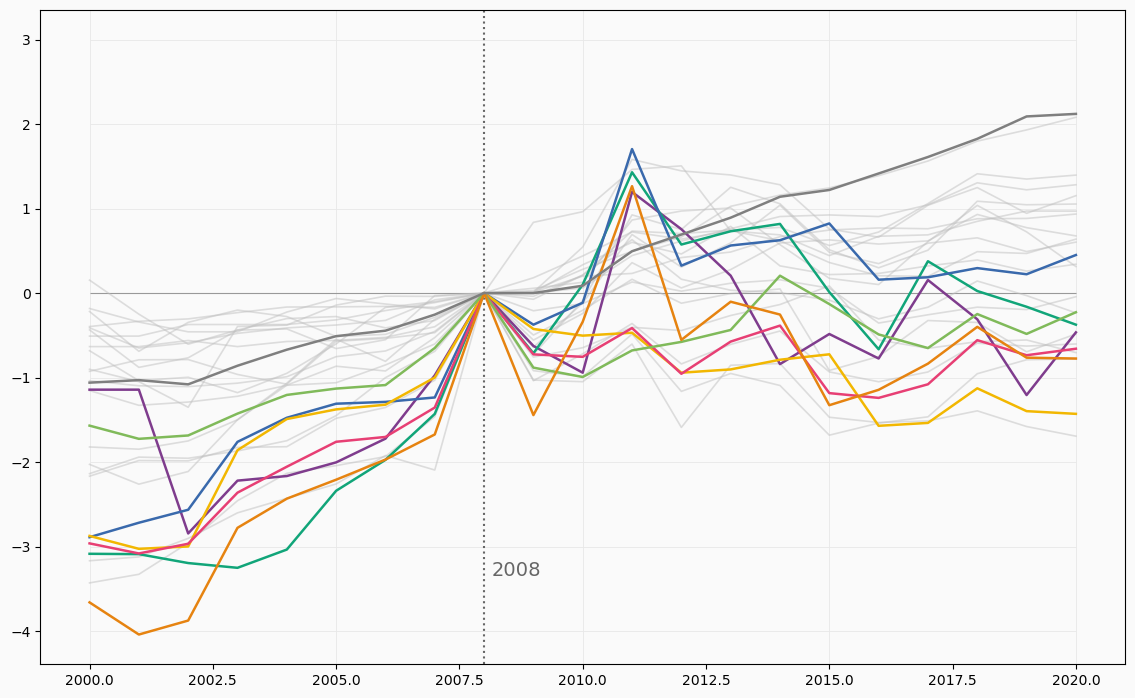

In [195]:
# Initialize layout ----------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8.5))

# Background color
fig.patch.set_facecolor(GREY98)
ax.set_facecolor(GREY98)

# Vertical lines used as scale reference
for h in VLINES:
    ax.axvline(h, color=GREY91, lw=0.6, zorder=0)

# Horizontal lines
ax.hlines(y=np.arange(-4, 4), xmin=2000, xmax=2020, color=GREY91, lw=0.6)

# Darker horizontal line at y=0
ax.hlines(y=0, xmin=2000, xmax=2020, color=GREY60, lw=0.8)

# Vertical like at x = 2008
ax.axvline(2008, color=GREY40, ls="dotted")

# Annotations indicating the meaning of the vertical line
ax.text(
    2008.15,
    -3.35,
    "2008",
    fontname="Montserrat",
    fontsize=14,
    fontweight=500,
    color=GREY40,
    ha="left",
)

# Add lines ------------------------------------------------------
# Create one data frame for the highlighted countries, and other
# for non-highlighted countries.
df_highlight = df_mac_indexed_2008[df_mac_indexed_2008["group"] != "other"]
df_others = df_mac_indexed_2008[df_mac_indexed_2008["group"] == "other"]

for group in df_others["iso_a3"].unique():
    data = df_others[df_others["iso_a3"] == group]
    ax.plot("year", "price_rel", c=GREY75, lw=1.2, alpha=0.5, data=data)

for idx, group in enumerate(df_highlight["iso_a3"].unique()):
    data = df_highlight[df_highlight["iso_a3"] == group]
    color = COLOR_SCALE[idx]
    ax.plot("year", "price_rel", color=color, lw=1.8, data=data)

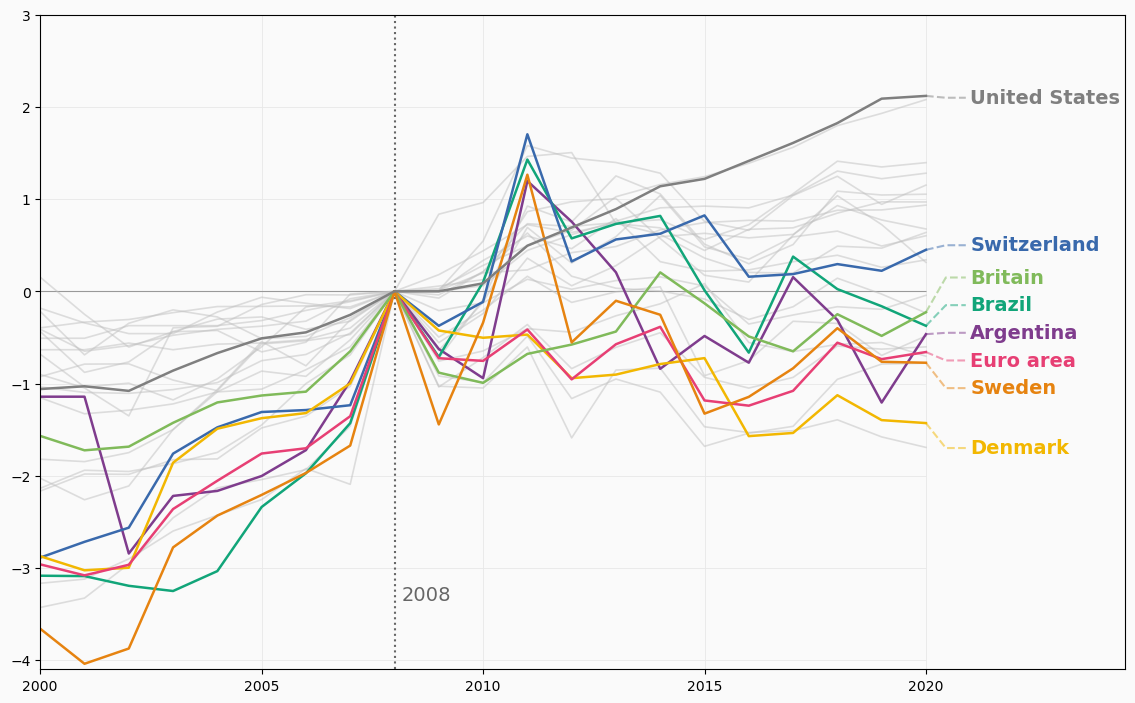

In [196]:
# First, adjust axes limits so annotations fit in the plot
ax.set_xlim(2000, 2024.5)
ax.set_ylim(-4.1, 3)

# Positions
LABEL_Y = [
    -0.45,  # ARG
    -0.15,  # BRA
    0.5,  # CHE
    -1.7,  # DNK
    -0.75,  # EUZ
    0.15,  # GBR
    -1.05,  # SWE
    2.1,  # USA
]

x_start = 2020
x_end = 2021
PAD = 0.1

# Add labels for highlighted countries honly
for idx, group in enumerate(df_highlight["iso_a3"].unique()):
    data = df_highlight[
        (df_highlight["iso_a3"] == group) & (df_highlight["year"] == 2020)
    ]
    color = COLOR_SCALE[idx]

    # Country name
    text = data["name"].values[0]

    # Vertical start of line
    y_start = data["price_rel"].values[0]
    # Vertical end of line
    y_end = LABEL_Y[idx]

    # Add line based on three points
    ax.plot(
        [x_start, (x_start + x_end - PAD) / 2, x_end - PAD],
        [y_start, y_end, y_end],
        color=color,
        alpha=0.5,
        ls="dashed",
    )

    # Add country text
    ax.text(
        x_end,
        y_end,
        text,
        color=color,
        fontsize=14,
        weight="bold",
        fontfamily="Montserrat",
        va="center",
    )
fig

In [197]:
max_size_MB_cumsum_per_model = df_groupby.group_by("Model").agg(
    [pl.col("size_MB_cumsum").max().alias("max_size_MB_cumsum")]
)

print(max_size_MB_cumsum_per_model)

shape: (86, 2)
┌───────────────────────────────────┬────────────────────┐
│ Model                             ┆ max_size_MB_cumsum │
│ ---                               ┆ ---                │
│ str                               ┆ i64                │
╞═══════════════════════════════════╪════════════════════╡
│ 454 GS FLX+                       ┆ 1560856            │
│ AB 5500xl-W Genetic Analysis Sys… ┆ 1264288            │
│ Illumina Genome Analyzer II       ┆ 226505193          │
│ Illumina MiSeq                    ┆ 62                 │
│ Illumina HiSeq 1500               ┆ 92056431           │
│ …                                 ┆ …                  │
│ Helicos HeliScope                 ┆ 1969501            │
│ 454 GS 20                         ┆ 120864             │
│ NextSeq 500                       ┆ 1025912597         │
│ AB 3500 Genetic Analyzer          ┆ 34                 │
│ 454 GS Junior                     ┆ 290220             │
└───────────────────────────────────┴────

In [198]:
for var, val in max_size_MB_cumsum_per_model.iter_rows():
    print(var)
    print(val)

454 GS FLX+
1560856
AB 5500xl-W Genetic Analysis System
1264288
Illumina Genome Analyzer II
226505193
Illumina MiSeq 
62
Illumina HiSeq 1500
92056431
NextSeq 2000
104966839
AB SOLiD System
1437027
GridION
48433851
AB SOLiD PI System
28747
Revio
5390136
PacBio RS
75917339
DNBSEQ-G400
174122181
PacBio RS II
196790821
Illumina iSeq 100
2171402
AB SOLiD 4 System
35430707
Illumina HiSeq 3000
340447261
AB 3500xL Genetic Analyzer
2161
AB 3130 Genetic Analyzer
4315
Illumina HiSeq 2500
3506703399
Sequel II
179371090
AB 3730 Genetic Analyzer
5395
Ion GeneStudio S5
847969
unspecified
61398329
454 GS FLX
3967951
Illumina HiSeq X
192164903
Illumina MiSeq  
15
Element AVITI
8584417
Ion S5 XL
386241
AB SOLiD 3 Plus System
938365
Illumina NovaSeq X
6216673
AB 5500 Genetic Analyzer
5605357
Sequel IIe
13847841
454 GS FLX Titanium
13210151
DNBSEQ-G50
6597800
FASTASeq 300
568
GS111
21908
DNBSEQ-T7
294612639
NextSeq 550
219477713
HiSeq X Ten
6937517732
Sequel
53203069
Illumina Genome Analyzer
45224019
AB S

First I write a function that iterates over a number of variables to plot and group by. The x-axis for all of these plots will be the release date.

In [199]:
import polars as pl

# Example DataFrame
df2 = pl.DataFrame({"species": ["cat", "dog", "bird", "fish"]})

# Your mapping dictionary
mapping_dict = {
    "cat": "feline",
    "dog": "canine",
    "bird": "avian"
    # Note: "fish" not included in the mapping, it will remain unchanged.
}

# Replace values in the 'species' column based on the mapping dictionary
df2 = df2.with_columns(pl.col("species").replace(mapping_dict))

print(df2)

shape: (4, 1)
┌─────────┐
│ species │
│ ---     │
│ str     │
╞═════════╡
│ feline  │
│ canine  │
│ avian   │
│ fish    │
└─────────┘


In [200]:
df_groupby

ReleaseDate_YM,Model,size_MB_sum,size_MB_cumsum
f64,str,i64,i64
2007.416667,"""454 GS FLX""",48040,48040
2008.25,"""454 GS 20""",10164,10164
2008.25,"""454 GS FLX""",81515,129555
2008.25,"""Illumina Genom…",136092,136092
2008.333333,"""454 GS 20""",329,10493
2008.333333,"""454 GS FLX""",8095,137650
2008.416667,"""454 GS 20""",90,10583
2008.416667,"""454 GS FLX""",4471,142121
2008.416667,"""Illumina Genom…",200678,336770


In [201]:
def plot_cumsum(df, vars_groupby, vars_toplot):
    for var_groupby in vars_groupby:
        for var_toplot in vars_toplot:
            df_groupby = (
                df.group_by(["ReleaseDate_YM", var_groupby])
                .agg([pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")])
                .sort(["ReleaseDate_YM", var_groupby])
            )

            # first compute the cumulative sum within each group
            df_groupby = df_groupby.group_by(var_groupby).map_groups(
                lambda group_df: group_df.with_columns(
                    pl.col(f"{var_toplot}_sum").cum_sum().alias(f"{var_toplot}_cumsum")
                )
            )

            # need to sort by 'ReleaseDate_YM' after the grouping operation
            df_groupby = df_groupby.sort(["ReleaseDate_YM", var_groupby])
            df_groupby = df_groupby.drop_nulls()

            fig, ax = plt.subplots()

            sns.lineplot(
                data=df_groupby.to_pandas(),  # Convert to Pandas DataFrame for seaborn compatibility
                x="ReleaseDate_YM",
                y=f"{var_toplot}_cumsum",
                ax=ax,
                hue=var_groupby,
            )

            ax.set_xticks(range(2007, 2025, 1))
            ax.set_xticklabels(labels=range(2007, 2025, 1), rotation=45)
            ax.set_yscale("log")

            # now let's start adding labels to each of these lines.
            # first i need to know the maximum value achieved
            df_max_cumsum = df_groupby.group_by(var_groupby).agg(
                [pl.col(f"{var_toplot}_cumsum").max().alias(f"{var_toplot}_cumsum_max")]
            )

            # then iterate over the rows of this polars df
            for var_groupby_value, max_val in df_max_cumsum.iter_rows():
                # Find the ReleaseDate_YM corresponding to this max_cumsum for the current model
                max_x = df_groupby.select(pl.col("ReleaseDate_YM").max()).to_numpy()[0][
                    0
                ]

                # Draw the label on the plot
                ax.text(
                    max_x,
                    max_val,
                    var_groupby_value,
                    horizontalalignment="left",
                    verticalalignment="center",
                )

            plt.legend(loc=(1.04, 0))
            plt.show()

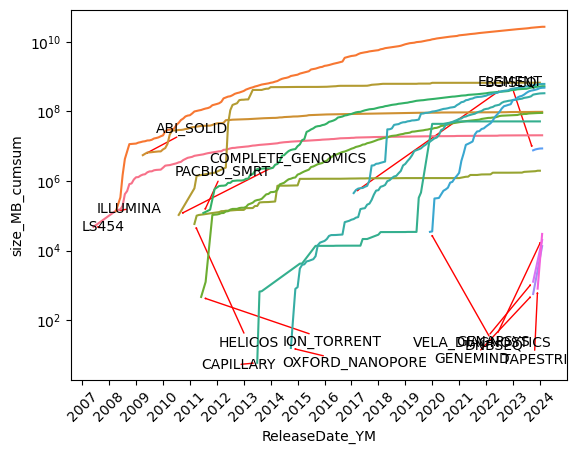

In [202]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
from adjustText import adjust_text


def plot_cumsum(df, vars_groupby, vars_toplot):
    fig, ax = plt.subplots()

    for var_groupby in vars_groupby:
        for var_toplot in vars_toplot:
            df_groupby = (
                df.group_by(["ReleaseDate_YM", var_groupby])
                .agg([pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")])
                .sort(["ReleaseDate_YM", var_groupby])
            )

            # Compute the cumulative sum within each group
            df_groupby = df_groupby.group_by(var_groupby).map_groups(
                lambda group_df: group_df.with_columns(
                    pl.col(f"{var_toplot}_sum").cum_sum().alias(f"{var_toplot}_cumsum")
                )
            )

            # Sort by 'ReleaseDate_YM' after the grouping operation
            df_groupby = df_groupby.sort(["ReleaseDate_YM", var_groupby])
            df_groupby = df_groupby.drop_nulls()

            sns.lineplot(
                data=df_groupby,
                x="ReleaseDate_YM",
                y=f"{var_toplot}_cumsum",
                ax=ax,
                hue=var_groupby,
            )

            ax.set_xticks(range(2007, 2025, 1))
            ax.set_xticklabels(labels=range(2007, 2025, 1), rotation=45)
            ax.set_yscale("log")

            # Now let's adjust label positions to avoid collisions at the start of each line
            texts = []

            for group_value in df_groupby[var_groupby].unique():
                group_df = df_groupby.filter(pl.col(var_groupby) == group_value)
                start_x = (
                    group_df.select(pl.col("ReleaseDate_YM")).min().to_numpy()[0][0]
                )
                start_y = (
                    group_df.select(pl.col(f"{var_toplot}_cumsum"))
                    .min()
                    .to_numpy()[0][0]
                )

                texts.append(
                    ax.text(
                        start_x,
                        start_y,
                        group_value,
                        horizontalalignment="left",
                        verticalalignment="center",
                        clip_on=True,  # Ensure text is clipped at plot boundaries
                    )
                )

            # Use adjust_text to optimize label placement
            adjust_text(
                texts,
                ax=ax,
                arrowprops=dict(arrowstyle="->", color="red"),
                objects=ax.get_lines(),
            )

            ax.get_legend().remove()
            plt.show()


# Example usage
texts = plot_cumsum(df, ["Platform"], ["size_MB"])

In [203]:
pos_x = texts[0].get_position()[0]
pos_y = texts[0].get_position()[1]
bounding_box = texts[0].get_window_extent(renderer=fig.canvas.get_renderer())
width = bounding_box.width
# height = bounding_box.height

pos_x_new = 2025 + (2025 - pos_x) + width
texts[0].set_position((pos_x_new, pos_y))

TypeError: 'NoneType' object is not subscriptable

In [ ]:
plt.show()

In [ ]:
vars_groupby = ["Platform", "LibraryStrategy", "Model"]
vars_toplot = ["spots", "size_MB"]

plot_cumsum(df, vars_groupby, vars_toplot)

In [ ]:
var_groupby = "ScientificName"
var_toplot = "size_MB"

df_groupby = (
    df.group_by([var_groupby]).agg(
        [pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")]
    )  # Sum of 'spots' within each group
).sort(["size_MB_sum"], descending=True)


df_groupby

In [ ]:
df_groupby.top_k(20, by="size_MB_sum")

In [ ]:
# Get the top 20 species by size_MB sum
top_species_df = df.groupby(var_groupby).agg(
    pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")
).sort(f"{var_toplot}_sum", descending=True).limit(20)

# Extract the names of the top 20 species
top_species = top_species_df[var_groupby].to_list()

# Add a new column to 'df' where species names not in the top 20 are replaced with "Other"
df = df.with_columns(
    pl.when(pl.col(var_groupby).is_in(top_species))
    .then(pl.col(var_groupby))
    .otherwise("Other")
    .alias(f"{var_groupby}_adjusted")
)


In [ ]:
if var_groupby in df.columns:
    # Add a new column to 'df' where species names not in the top 20 are replaced with "Other"
    df = df.with_columns(
        pl.when(pl.col(var_groupby).is_in(top_species))
        .then(pl.col(var_groupby))
        .otherwise(
            pl.lit("Other")
        )  # Use pl.lit to explicitly treat "Other" as a literal value
        .alias(f"{var_groupby}_adjusted")
    )
else:
    print(f"Column '{var_groupby}' not found in DataFrame.")

In [ ]:
df

In [ ]:
# then groupby
vars_groupby = ["ScientificName_adjusted"]
vars_toplot = ["spots", "bases", "size_MB"]

for var_groupby in vars_groupby:
    for var_toplot in vars_toplot:
        df_groupby = (
            df.group_by(["ReleaseDate_YM", var_groupby])
            .agg(
                [pl.col(var_toplot).sum().alias(f"{var_toplot}_sum")]
            )  # Sum of 'spots' within each group
            .sort(
                ["ReleaseDate_YM", var_groupby]
            )  # Sort by 'ReleaseDate_YM' and then 'Platform'
        )
        fig, ax = plt.subplots()

        sns.lineplot(
            data=df_groupby,
            x="ReleaseDate_YM",
            y=f"{var_toplot}_sum",
            ax=ax,
            hue=var_groupby,
        )
        # ax.set_xticklabels(range(2007, 2025, 1))
        plt.xticks(range(2007, 2025, 1))
        ax.set_xticklabels(labels=range(2007, 2025, 1), rotation=45)
        ax.set_yscale("log")
        plt.legend(loc=(1.04, 0))
        plt.show()
        plt.close()

        # compute the cumulative sum within each 'Platform' group, respecting the 'ReleaseDate_YM' ordering
        df_groupby = df_groupby.group_by(var_groupby).map_groups(
            lambda group_df: group_df.with_columns(
                pl.col(f"{var_toplot}_sum").cum_sum().alias(f"{var_toplot}_cumsum")
            )
        )

        # sort again by 'ReleaseDate_YM' after the grouping operation
        df_groupby = df_groupby.sort(["ReleaseDate_YM", var_groupby])
        df_groupby = df_groupby.drop_nulls()

        # plot
        fig, ax = plt.subplots()

        sns.lineplot(
            data=df_groupby,
            x="ReleaseDate_YM",
            y=f"{var_toplot}_cumsum",
            ax=ax,
            hue=var_groupby,
        )
        # ax.set_xticklabels(range(2007, 2025, 1))
        plt.xticks(range(2007, 2025, 1))
        ax.set_xticklabels(labels=range(2007, 2025, 1), rotation=45)
        ax.set_yscale("log")
        plt.legend(loc=(1.04, 0))
        plt.show()
        plt.close()